In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Modelling Exercise 2g, 2h and 2i


# Number of particles and bonds
N = 17
Nb = N - 1


# Dimensionless units Exercise 2h

zeta = 1.0
kBT = 1.0
l0 = 1.0

# From <l_i^2> = 3 kBT / K and l0^2 = <l_i^2>
K = 3.0

# Characteristic diffusion time
tau = zeta * l0**2 / kBT

# Integration timestep
dt = 0.01 * tau

# Number of integration steps
M = 10000

print("K =", K)
print("tau =", tau)
print("dt =", dt)

K = 3.0
tau = 1.0
dt = 0.01


In [2]:

# Initial configuration


r = np.zeros((N, 3))

# Fully stretched chain along x
r[:, 0] = np.arange(N) * l0

rng = np.random.default_rng(1)

r = rng.normal(0, 1, size=(N, 3))
r_initial = r.copy()
def spring_forces(r, K):
    """
    Calculate Hookean spring forces for all 17 particles.
    """

    N = len(r)
    F = np.zeros_like(r)

    # First particle
    F[0] = K * (r[1] - r[0])

    # Internal particles
    F[1:-1] = K * (r[:-2]+r[2:] - 2 * r[1:-1])

    # Last particle
    F[-1] = K * (r[-2] - r[-1])

    return F

# Exercise 2i: simulation no random forces


# Reset initial configuration
r = r_initial.copy()



# Store potential energy and mean bond length
energies = []
mean_bond_lengths = []
trajectory = []
save_every = 20

for step in range(M):

    # Potential spring forces
    F = spring_forces(r, K)

    # No random force in Exercise 2i
    R = np.zeros_like(r)

    # finite difference update
    r += (dt / zeta) * (F + R)

    # Calculate properties
    bonds = r[1:] - r[:-1]
    bond_squared = np.sum(bonds**2, axis=1)

    U = 0.5 * K * np.sum(bond_squared)
    mean_bond_length = np.mean(np.sqrt(bond_squared))

    energies.append(U)
    mean_bond_lengths.append(mean_bond_length)

    if step % save_every == 0:
        trajectory.append(r.copy())




r_final = r.copy()
trajectory = np.array(trajectory)

In [3]:

# Check final state


final_bonds = r_final[1:] - r_final[:-1]
final_bond_lengths = np.linalg.norm(final_bonds, axis=1)



print("Mean final bond length:", np.mean(final_bond_lengths))
print("Maximum final bond length:", np.max(final_bond_lengths))

print("\nFinal particle positions:")
print(r_final)

Mean final bond length: 3.1897141376732854e-06
Maximum final bond length: 4.708955050260635e-06

Final particle positions:
[[-0.06801971 -0.10491778  0.0857083 ]
 [-0.06801916 -0.10491841  0.08570806]
 [-0.06801808 -0.10491964  0.08570758]
 [-0.0680165  -0.10492144  0.08570689]
 [-0.06801449 -0.10492374  0.085706  ]
 [-0.0680121  -0.10492647  0.08570495]
 [-0.06800942 -0.10492952  0.08570378]
 [-0.06800654 -0.10493281  0.08570251]
 [-0.06800355 -0.10493621  0.0857012 ]
 [-0.06800057 -0.10493961  0.08569989]
 [-0.06799769 -0.1049429   0.08569863]
 [-0.06799501 -0.10494595  0.08569745]
 [-0.06799262 -0.10494868  0.0856964 ]
 [-0.0679906  -0.10495098  0.08569551]
 [-0.06798903 -0.10495278  0.08569482]
 [-0.06798794 -0.10495401  0.08569434]
 [-0.06798739 -0.10495464  0.0856941 ]]


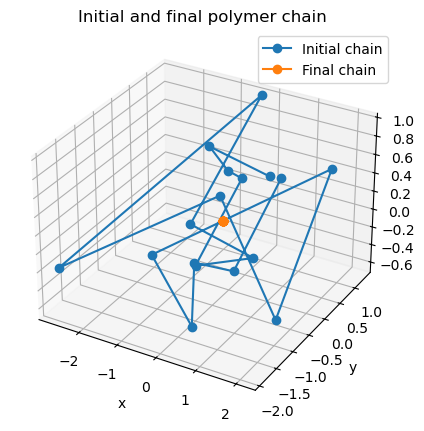

In [4]:
# Plot initial and final chain

fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(111, projection="3d")

ax.plot(r_initial[:, 0], r_initial[:, 1], r_initial[:, 2],
        "o-", label="Initial chain")

ax.plot(r_final[:, 0], r_final[:, 1], r_final[:, 2],
        "o-", label="Final chain")

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

ax.set_title("Initial and final polymer chain")
ax.legend()

plt.show()

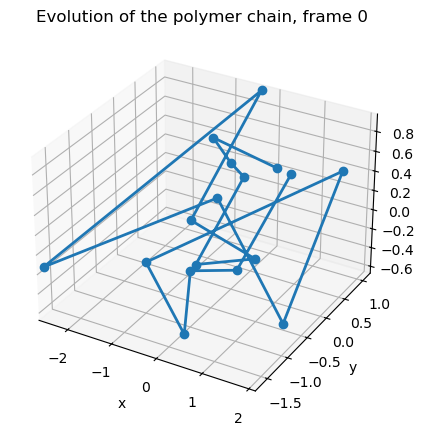

In [5]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(111, projection="3d")

line, = ax.plot([], [], [], "o-", lw=2)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Evolution of the polymer chain")

# Set axis limits based on trajectory
xmin = trajectory[:, :, 0].min()
xmax = trajectory[:, :, 0].max()
ymin = trajectory[:, :, 1].min()
ymax = trajectory[:, :, 1].max()
zmin = trajectory[:, :, 2].min()
zmax = trajectory[:, :, 2].max()

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_zlim(zmin, zmax)

def update(frame):
    coords = trajectory[frame]
    line.set_data(coords[:, 0], coords[:, 1])
    line.set_3d_properties(coords[:, 2])
    ax.set_title(f"Evolution of the polymer chain, frame {frame}")
    return line,

ani = FuncAnimation(fig, update, frames=len(trajectory), interval=100, blit=False)

ani.save("chain_evolution.gif", writer="pillow", fps=10)